**Google Colab was used to provide sufficient computational resources and to prevent excessive load on local hardware.**

---
## Get Libraries and Data
---

In [ ]:
!pip install matminer
!pip install mp_api

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.6/55.6 kB 3.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.9/51.9 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 15.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 331.1/331.1 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 962.5/962.5 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.1/60.1 kB 1.7 MB/s eta 0:00:00
  Created wheel for bibtexparser: filename=bibtexparser-1.4.3-py3-none-any.whl size=43549 sha256=495e64930a886468a994b4219a015736e8244fcf9910619b5336bbd60ed38c7e
  Stored

In [ ]:
from mp_api.client import MPRester
from pymatgen.core import Composition
from matminer.featurizers.composition import ElementProperty
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score
from xgboost import XGBRegressor, XGBClassifier
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler    # normalize

In [ ]:
mpr = MPRester("5YwibZ6nxZLfuJuM6pf1zggxwgLYLfej")

# what I want to obtain/predict to compare with DFT calculations
data = mpr.materials.summary.search(
    fields=["material_id", "formula_pretty", "formation_energy_per_atom", "band_gap", "total_magnetization", "efermi","is_magnetic"],
    num_chunks=10
)

data = pd.DataFrame([i.dict() for i in data])
print(data)

# Small sample of the total data
data_small = data.sample(n=2000, random_state=42)

# Convert formula strings to pymatgen Composition objects
data_small["composition"] = data_small["formula_pretty"].apply(Composition)
ep = ElementProperty.from_preset("magpie", impute_nan=True)

# Add "Composition" Column
data_features = ep.featurize_dataframe(data_small, col_id="composition", ignore_errors=True)

# Features: all numerical columns calculated by Magpie, except the ones from DFT (drop)

X = data_features.drop(columns=[
    "material_id",
    "formula_pretty",
    "composition",
    "band_gap",
    "formation_energy_per_atom",
    "efermi",
    "total_magnetization",
    "is_magnetic"
], errors="ignore")

# Select only float or int
X_numeric = X.select_dtypes(include=[np.number]).copy()
X = X.select_dtypes(include=[np.number])

# Remove columns with arrays
X = X.loc[:, X.map(np.isscalar).all()]  # data from Magpie

# NaNs to zero
X_numeric.fillna(0, inplace=True)

# One output
y_energy = data_features["band_gap"]

Retrieving SummaryDoc documents:   0%|          | 0/10000 [00:00<?, ?it/s]

     formula_pretty material_id  formation_energy_per_atom  band_gap  \
0                Nb    mp-ckgno                   0.189748    0.0000   
1                Si    mp-cltmd                   0.372510    0.0000   
2                Rb    mp-cpdha                   0.053649    0.0000   
3                O2    mp-cpdoy                   0.419854    1.2773   
4                O2    mp-cpdrc                   0.387014    0.0423   
...             ...         ...                        ...       ...   
9995          Ta5N6      mp-cle                  -1.311067    0.0000   
9996         Ta5Ge3      mp-zej                  -0.322289    0.0000   
9997         Pr5Ge3      mp-ziq                  -0.790064    0.0000   
9998           LaF3      mp-zkl                  -4.363965    4.9199   
9999         Sc5Ge3      mp-zle                  -0.909267    0.0000   

        efermi  is_magnetic  total_magnetization  \
0     4.794354        False             0.000120   
1     5.218087        False    

ElementProperty:   0%|          | 0/2000 [00:00<?, ?it/s]



---

# Model 1: Random Forest
---

### Training/Test = 80/20 %

---


Train Sample results – Band Gap (eV):
MAE: 0.182, R^2: 0.894

Test Sample results – Band Gap (eV):
MAE: 0.361, R^2: 0.755


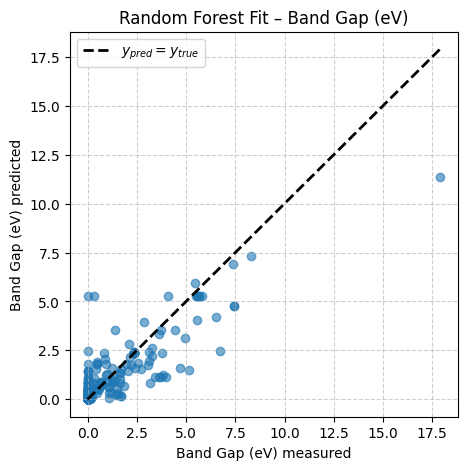


Train Sample results – Formation Energy (eV/atom):
MAE: 0.120, R^2: 0.933

Test Sample results – Formation Energy (eV/atom):
MAE: 0.242, R^2: 0.842


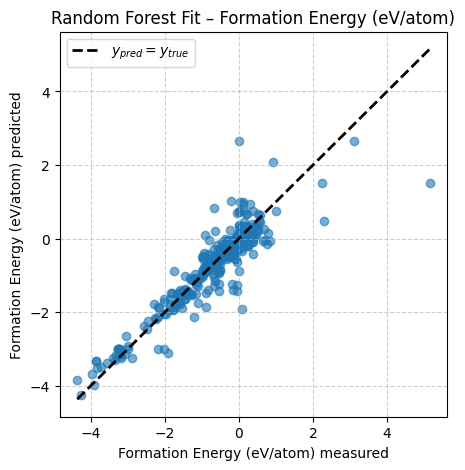


Train Sample results – Fermi Energy (eV):
MAE: 0.574, R^2: 0.886

Test Sample results – Fermi Energy (eV):
MAE: 1.132, R^2: 0.701


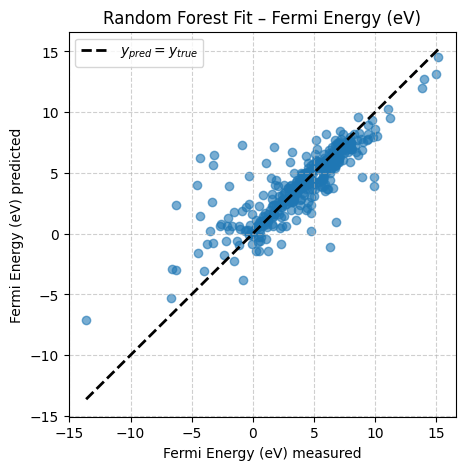


Train Sample results – Total Magnetization:
MAE: 1.415, R^2: 0.777

Test Sample results – Total Magnetization:
MAE: 2.167, R^2: 0.250


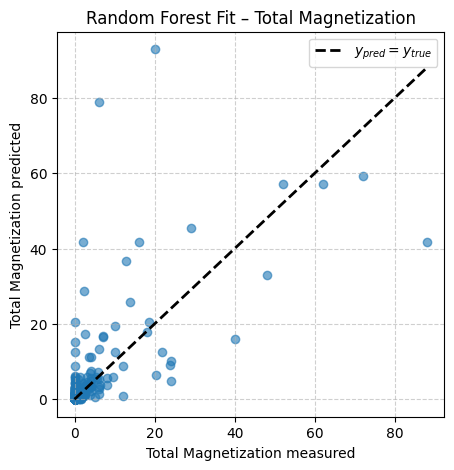


 Magnetic vs Non-magnetic 
  Accuracy: 0.915

 Metal vs Semiconductor 
  Accuracy: 0.885


In [ ]:
def rf_regression(X, y, name, clip_zero=False):

  # remove nans
  mask = y.notna()
  X = X.loc[mask]
  y = y.loc[mask]

  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

  rf = RandomForestRegressor(n_estimators=100, random_state=42)
  rf.fit(X_train, y_train)

  # -----------------------------------TRAIN----------------------------------------
  y_pred_train = rf.predict(X_train)

  if clip_zero:  # band_gap case
      y_pred_train = np.clip(y_pred_train, a_min=0, a_max=None)

  mae_train = mean_absolute_error(y_train, y_pred_train)
  r2_train = r2_score(y_train, y_pred_train)

  print(f"\nTrain Sample results – {name}:")
  print(f"MAE: {mae_train:.3f}, R^2: {r2_train:.3f}")

  # ----------------------------------- TEST ----------------------------------------
  y_pred_test = rf.predict(X_test)

  if clip_zero:
      y_pred_test = np.clip(y_pred_test, a_min=0, a_max=None)

  mae_test = mean_absolute_error(y_test, y_pred_test)
  r2_test = r2_score(y_test, y_pred_test)

  print(f"\nTest Sample results – {name}:")
  print(f"MAE: {mae_test:.3f}, R^2: {r2_test:.3f}")

  # --------------------------------- PLOT --------------------------------------
  plt.figure(figsize=(5,5))
  plt.scatter(y_test, y_pred_test, alpha=0.6)

  # y = x
  y_all = y_test.values
  identity = np.linspace(y_all.min(), y_all.max(), 100)
  plt.plot(identity, identity, 'k--', linewidth=2,label='$y_{pred}=y_{true}$')
  plt.xlabel(f"{name} measured")
  plt.ylabel(f"{name} predicted")
  plt.title(f"Random Forest Fit – {name}")
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.legend()
  plt.show()

  return rf

def rf_classification(X, y, name):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs = -1)  # n_jobs = -1 uses all available CPU cores

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print(f"\n {name} ")
    print(f"  Accuracy: {accuracy_score(y_test, y_pred):.3f}")

    return model


#------------------------------------- ALL PROPERTIES -------------------------------------

y_bandgap = data_features["band_gap"]
rf_bandgap = rf_regression(X, y_bandgap, "Band Gap (eV)", clip_zero=True)

y_formation = data_features["formation_energy_per_atom"]
rf_formation = rf_regression(X, y_formation, "Formation Energy (eV/atom)")

y_efermi = data_features["efermi"]
rf_efermi = rf_regression(X, y_efermi, "Fermi Energy (eV)")

y_magnetization = data_features["total_magnetization"]
rf_magnetization = rf_regression(X, y_magnetization, "Total Magnetization")

y_is_magnetic = data_features["is_magnetic"].astype(int)
rf_is_magnetic = rf_classification(X, y_is_magnetic, "Magnetic vs Non-magnetic")

y_metal = (data_features["band_gap"] < 0.01).astype(int)
rf_metal = rf_classification(X, y_metal, "Metal vs Semiconductor")



---

### K-cross validation method

---




Set 1 – Band Gap (eV)...
   MAE : 0.3543
   R^2 : 0.7529
Set 2 – Band Gap (eV)...
   MAE : 0.3492
   R^2 : 0.5864
Set 3 – Band Gap (eV)...
   MAE : 0.3740
   R^2 : 0.6434
Set 4 – Band Gap (eV)...
   MAE : 0.3073
   R^2 : 0.7199
Set 5 – Band Gap (eV)...
   MAE : 0.4169
   R^2 : 0.6977

Final Results: Band Gap (eV)
Average MAE (5 sets): 0.3603
Average R^2 (5 sets): 0.6801


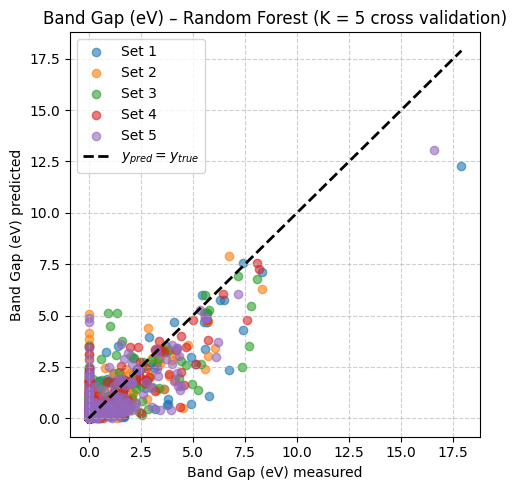

Set 1 – Formation Energy (eV/atom)...
   MAE : 0.2262
   R^2 : 0.8356
Set 2 – Formation Energy (eV/atom)...
   MAE : 0.2004
   R^2 : 0.8826
Set 3 – Formation Energy (eV/atom)...
   MAE : 0.2444
   R^2 : 0.8442
Set 4 – Formation Energy (eV/atom)...
   MAE : 0.2282
   R^2 : 0.7977
Set 5 – Formation Energy (eV/atom)...
   MAE : 0.2294
   R^2 : 0.8456

Final Results: Formation Energy (eV/atom)
Average MAE (5 sets): 0.2257
Average R^2 (5 sets): 0.8411


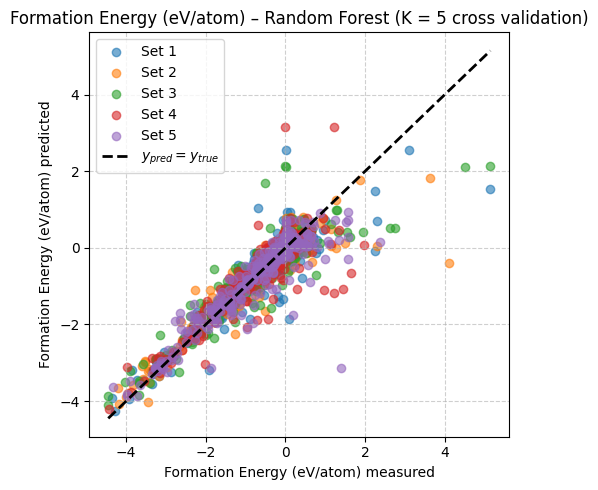

Set 1 – Fermi Energy (eV)...
   MAE : 1.0172
   R^2 : 0.7717
Set 2 – Fermi Energy (eV)...
   MAE : 1.0714
   R^2 : 0.6866
Set 3 – Fermi Energy (eV)...
   MAE : 1.1162
   R^2 : 0.6694
Set 4 – Fermi Energy (eV)...
   MAE : 1.0904
   R^2 : 0.6326
Set 5 – Fermi Energy (eV)...
   MAE : 1.1627
   R^2 : 0.7178

Final Results: Fermi Energy (eV)
Average MAE (5 sets): 1.0916
Average R^2 (5 sets): 0.6956


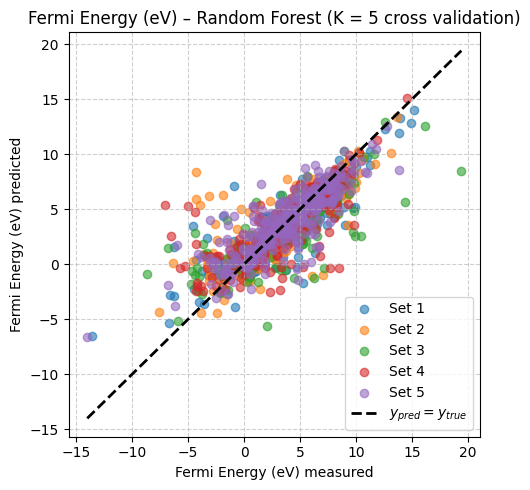

Set 1 – Magnetization...
   MAE : 2.3385
   R^2 : 0.2208
Set 2 – Magnetization...
   MAE : 3.5581
   R^2 : 0.4228
Set 3 – Magnetization...
   MAE : 3.3158
   R^2 : 0.2940
Set 4 – Magnetization...
   MAE : 2.5192
   R^2 : 0.3234
Set 5 – Magnetization...
   MAE : 2.5011
   R^2 : 0.3557

Final Results: Magnetization
Average MAE (5 sets): 2.8465
Average R^2 (5 sets): 0.3233


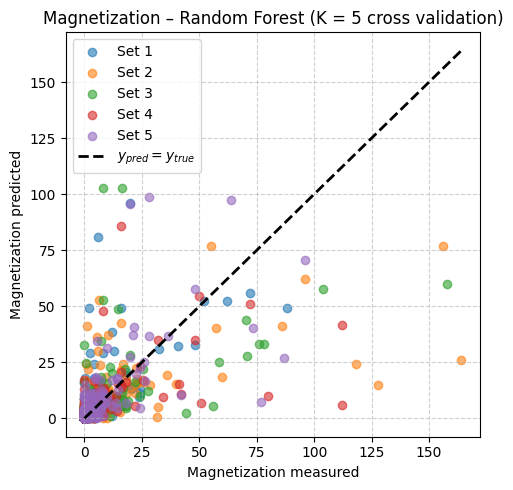

Set 1 – Magnetic vs Non Magnetic...
   Accuracy Fold 1: 0.9075
Set 2 – Magnetic vs Non Magnetic...
   Accuracy Fold 2: 0.8850
Set 3 – Magnetic vs Non Magnetic...
   Accuracy Fold 3: 0.8975
Set 4 – Magnetic vs Non Magnetic...
   Accuracy Fold 4: 0.8750
Set 5 – Magnetic vs Non Magnetic...
   Accuracy Fold 5: 0.8875

Final Results – Magnetic vs Non Magnetic
Average accuracy (5 folds): 0.8905

Set 1 – Metal vs Semiconductor...
   Accuracy Fold 1: 0.8875
Set 2 – Metal vs Semiconductor...
   Accuracy Fold 2: 0.8775
Set 3 – Metal vs Semiconductor...
   Accuracy Fold 3: 0.8750
Set 4 – Metal vs Semiconductor...
   Accuracy Fold 4: 0.8475
Set 5 – Metal vs Semiconductor...
   Accuracy Fold 5: 0.8475

Final Results – Metal vs Semiconductor
Average accuracy (5 folds): 0.8670



[0.8875, 0.8775, 0.875, 0.8475, 0.8475]

In [ ]:
#--------------------------------- REGRESSION ------------------------------------

def rf_kfold_cv(X, y, name, K, clip_zero=False):

    kf = KFold(n_splits=K, shuffle=True, random_state=42)
    modelo = RandomForestRegressor(n_estimators=100, random_state=42)

    fold_scores = np.zeros((K, 2))

    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

    plt.figure(figsize=(5, 5))

    for i, (train_index, test_index) in enumerate(kf.split(X)):
        print(f"Set {i+1} – {name}...")

        X_train, X_test = X.iloc[train_index], X.iloc[test_index]  #iloc to get row and column index (pandas)
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]

        modelo.fit(X_train, y_train)
        y_pred_test = modelo.predict(X_test)

        if clip_zero:
            y_pred_test = np.clip(y_pred_test, a_min=0, a_max=None)

        mae = mean_absolute_error(y_test, y_pred_test)
        r2 = r2_score(y_test, y_pred_test)

        fold_scores[i, 0] = r2
        fold_scores[i, 1] = mae

        print(f"   MAE : {mae:.4f}")
        print(f"   R^2 : {r2:.4f}")

        plt.scatter(y_test.values, y_pred_test, color=colors[i], alpha=0.6, label=f'Set {i+1}')

    # y = x
    y_all = y.values
    identity = np.linspace(y_all.min(), y_all.max(), 100)
    plt.plot(identity, identity, 'k--', linewidth=2,
             label='$y_{pred}=y_{true}$')

    print("\nFinal Results:", name)
    print(f"Average MAE ({K} sets): {np.mean(fold_scores[:,1]):.4f}")
    print(f"Average R^2 ({K} sets): {np.mean(fold_scores[:,0]):.4f}")

    plt.xlabel(f"{name} measured")
    plt.ylabel(f"{name} predicted")
    plt.title(f"{name} – Random Forest (K = {K} cross validation)")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

    return fold_scores

#--------------------------------- CLASSIFICATION ------------------------------------
def rf_kfold_classification(X, y, name, K):

    kf = KFold(n_splits=K, shuffle=True, random_state=42)
    modelo = RandomForestClassifier(n_estimators=100, random_state=42)

    accuracies = []

    for i, (train_index, test_index) in enumerate(kf.split(X)):
        print(f"Set {i+1} – {name}...")

        X_train, X_test = X.iloc[train_index], X.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]

        modelo.fit(X_train, y_train)
        y_pred = modelo.predict(X_test)

        acc = accuracy_score(y_test, y_pred)
        accuracies.append(acc)

        print(f"   Accuracy Fold {i+1}: {acc:.4f}")

    print(f"\nFinal Results – {name}")
    print(f"Average accuracy ({K} folds): {np.mean(accuracies):.4f}\n")

    return accuracies

X = X_numeric.copy()

#------------------------------------- Properties -------------------------------------
rf_kfold_cv(X,
    data_features["band_gap"],
    "Band Gap (eV)",5,
    clip_zero=True
)

rf_kfold_cv(
    X,
    data_features["formation_energy_per_atom"],
    "Formation Energy (eV/atom)",5,
    clip_zero=False
)

mask_efermi = data_features["efermi"].notna()

rf_kfold_cv(
    X.loc[mask_efermi],
    data_features.loc[mask_efermi, "efermi"],
    "Fermi Energy (eV)",5,
    clip_zero=False
)

mask_mag = data_features["total_magnetization"].notna()

rf_kfold_cv(
    X.loc[mask_mag],
    data_features.loc[mask_mag, "total_magnetization"],
    "Magnetization",5,
    clip_zero=False
)

rf_kfold_classification(
    X,
    data_features["is_magnetic"].astype(int),
    "Magnetic vs Non Magnetic",5
)

y_metal = (data_features["band_gap"] < 0.01).astype(int)

rf_kfold_classification(
    X,
    y_metal,
    "Metal vs Semiconductor",5
)

---

### Random Subsampling (80% train, 20% test)

---


 BAND GAP

Random Subsampling (10 sets)
   Set 1 R^2: 0.7442
   Set 2 R^2: 0.7497
   Set 3 R^2: 0.5164
   Set 4 R^2: 0.5416
   Set 5 R^2: 0.6761
   Set 6 R^2: 0.5588
   Set 7 R^2: 0.7669
   Set 8 R^2: 0.6897
   Set 9 R^2: 0.5545
   Set 10 R^2: 0.6057


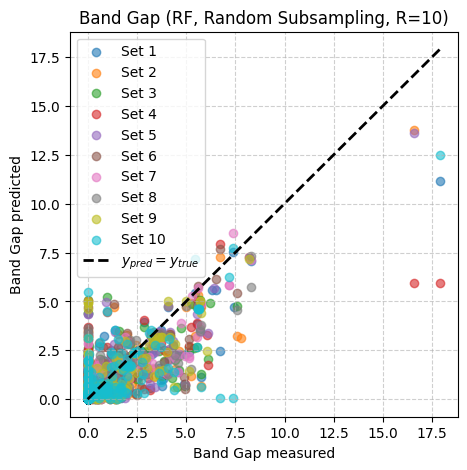


Final Results:
Average R^2: 0.6404
R^2 standard deviation: 0.0910

 FORMATION ENERGY

Random Subsampling (10 sets)
   Set 1 R^2: 0.8327
   Set 2 R^2: 0.8756
   Set 3 R^2: 0.7463
   Set 4 R^2: 0.8175
   Set 5 R^2: 0.8390
   Set 6 R^2: 0.8178
   Set 7 R^2: 0.8237
   Set 8 R^2: 0.8659
   Set 9 R^2: 0.7554
   Set 10 R^2: 0.8142


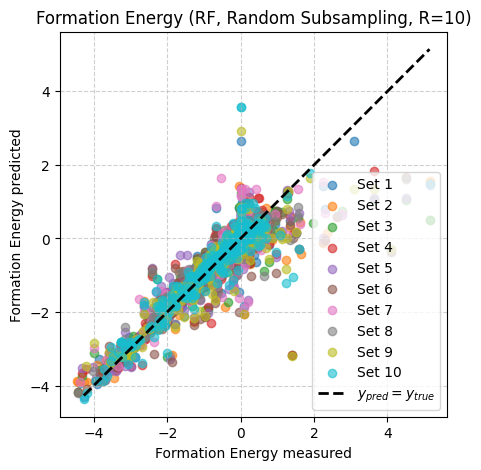


Final Results:
Average R^2: 0.8188
R^2 standard deviation: 0.0392

 FERMI ENERGY

Random Subsampling (10 sets)
   Set 1 R^2: 0.7704
   Set 2 R^2: 0.7127
   Set 3 R^2: 0.6647
   Set 4 R^2: 0.7450
   Set 5 R^2: 0.7430
   Set 6 R^2: 0.6456
   Set 7 R^2: 0.6874
   Set 8 R^2: 0.6893
   Set 9 R^2: 0.6229
   Set 10 R^2: 0.6587


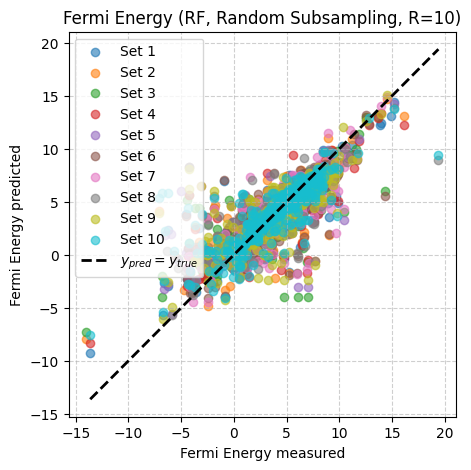


Final Results:
Average R^2: 0.6940
R^2 standard deviation: 0.0456

 TOTAL MAGNETIZATION

Random Subsampling (10 sets)
   Set 1 R^2: 0.2594
   Set 2 R^2: 0.4057
   Set 3 R^2: 0.3020
   Set 4 R^2: 0.4790
   Set 5 R^2: 0.3516
   Set 6 R^2: 0.3531
   Set 7 R^2: 0.5795
   Set 8 R^2: 0.4382
   Set 9 R^2: 0.2312
   Set 10 R^2: 0.4105


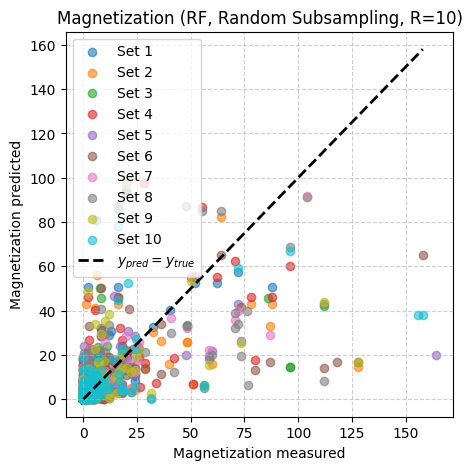


Final Results:
Average R^2: 0.3810
R^2 standard deviation: 0.0994

 MAGNETIC vs NON MAGNETIC 


Random Subsampling (10 sets) --- Magnetic vs Non-magnetic
Set 1...
   Accuracy Set 1: 0.9125
Set 2...
   Accuracy Set 2: 0.9000
Set 3...
   Accuracy Set 3: 0.8825
Set 4...
   Accuracy Set 4: 0.8825
Set 5...
   Accuracy Set 5: 0.8750
Set 6...
   Accuracy Set 6: 0.8850
Set 7...
   Accuracy Set 7: 0.8875
Set 8...
   Accuracy Set 8: 0.8825
Set 9...
   Accuracy Set 9: 0.9075
Set 10...
   Accuracy Set 10: 0.8850

Final Results:
Average Accuracy: 0.8900
Accuracy standard deviation: 0.0117

 METAL vs SEMICONDUCTOR 


Random Subsampling (10 sets) --- Metal vs Semiconductor
Set 1...
   Accuracy Set 1: 0.8750
Set 2...
   Accuracy Set 2: 0.8850
Set 3...
   Accuracy Set 3: 0.8525
Set 4...
   Accuracy Set 4: 0.8525
Set 5...
   Accuracy Set 5: 0.8700
Set 6...
   Accuracy Set 6: 0.8450
Set 7...
   Accuracy Set 7: 0.8800
Set 8...
   Accuracy Set 8: 0.8600
Set 9...
   Accuracy Set 9: 0.8675
Set 10...
   Accu

In [ ]:
def random_subsampling_rf(X_numeric, y_energy, name, clip_zero=True):

  # remove nans
  mask_not_nan = y_energy.notna()
  X_temp = X_numeric.loc[mask_not_nan]
  y_temp = y_energy.loc[mask_not_nan]

  mask_finite = np.isfinite(y_temp)
  X_clean = X_temp.loc[mask_finite]
  y_clean = y_temp.loc[mask_finite]

  R = 10  # random splits
  TEST_SIZE = 0.2

  modelo = RandomForestRegressor(
      n_estimators=100,
      random_state=42,
      n_jobs=-1
  )

  repetition_scores = []

  colors = [
      '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd',
      '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf'
  ]

  print(f"Random Subsampling ({R} sets)")

  plt.figure(figsize=(5,5))
  for i in range(R):
      X_train, X_test, y_train, y_test = train_test_split(
          X_clean,
          y_clean,
          test_size=TEST_SIZE,
          random_state=42 + i,   # different seed
          shuffle=True
      )

      modelo.fit(X_train, y_train)

      y_pred_test_rf = modelo.predict(X_test)

      # Band_gap > 0
      if clip_zero:
        y_pred_test_rf = np.clip(y_pred_test_rf, a_min=0, a_max=None)

      r2 = r2_score(y_test, y_pred_test_rf)
      repetition_scores.append(r2)
      print(f"   Set {i+1} R^2: {r2:.4f}")


      plt.scatter(y_test.values, y_pred_test_rf, color=colors[i], alpha=0.6, label=f'Set {i+1}')

  # y = x
  y_all = y_test.values
  identity = np.linspace(y_all.min(), y_all.max(), 100)
  plt.plot(identity, identity, 'k--', linewidth=2,label='$y_{pred}=y_{true}$')
  plt.xlabel(f"{name} measured")
  plt.ylabel(f"{name} predicted")
  plt.title(f"{name} (RF, Random Subsampling, R={R})")

  plt.grid(True, linestyle='--', alpha=0.6)
  plt.legend()
  plt.show()


  final_mean_r2 = np.mean(repetition_scores)

  print("\nFinal Results:")
  print(f"Average R^2: {final_mean_r2:.4f}")
  print(f"R^2 standard deviation: {np.std(repetition_scores):.4f}")

  return repetition_scores


def random_subsampling_rf_classification(X_numeric, y_class, name):

    mask_not_nan = y_class.notna()
    X_temp = X_numeric.loc[mask_not_nan]
    y_temp = y_class.loc[mask_not_nan]

    mask_finite = np.isfinite(y_temp)
    X_clean = X_temp.loc[mask_finite]
    y_clean = y_temp.loc[mask_finite]

    R = 10
    TEST_SIZE = 0.2

    modelo = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    repetition_scores = []

    print(f"\nRandom Subsampling ({R} sets) --- {name}")

    for i in range(R):
        X_train, X_test, y_train, y_test = train_test_split(
            X_clean,
            y_clean,
            test_size=TEST_SIZE,
            random_state=42 + i,
            shuffle=True
        )

        print(f"Set {i+1}...")

        modelo.fit(X_train, y_train)

        y_pred = modelo.predict(X_test)

        acc = accuracy_score(y_test, y_pred)
        repetition_scores.append(acc)

        print(f"   Accuracy Set {i+1}: {acc:.4f}")

    # FINAL
    mean_acc = np.mean(repetition_scores)
    std_acc = np.std(repetition_scores)

    print("\nFinal Results:")
    print(f"Average Accuracy: {mean_acc:.4f}")
    print(f"Accuracy standard deviation: {std_acc:.4f}")

    return repetition_scores

#------------------------------------- PROPERTIES -------------------------------------
print("\n BAND GAP\n")
scores_bandgap = random_subsampling_rf(X_numeric, y_bandgap, "Band Gap", clip_zero=True)

print("\n FORMATION ENERGY\n")
scores_formation = random_subsampling_rf(X_numeric, y_formation, "Formation Energy", clip_zero=False)

print("\n FERMI ENERGY\n")
scores_efermi = random_subsampling_rf(X_numeric, y_efermi, "Fermi Energy", clip_zero=False)

print("\n TOTAL MAGNETIZATION\n")
scores_magnetization = random_subsampling_rf(X_numeric, y_magnetization, "Magnetization", clip_zero=False)

print("\n MAGNETIC vs NON MAGNETIC \n")
scores_magnetic = random_subsampling_rf_classification(
    X_numeric,
    y_is_magnetic,
    "Magnetic vs Non-magnetic"
)

print("\n METAL vs SEMICONDUCTOR \n")
scores_metal = random_subsampling_rf_classification(
    X_numeric,
    y_metal,
    "Metal vs Semiconductor"
)



---

# Model 2: XGBoost

---

---
### Training/Test = 80/20 %
---


Train Sample Results – Band Gap:
MAE: 0.103, R^2: 0.935

Test Sample Results – Band Gap:
MAE: 0.326, R^2: 0.798



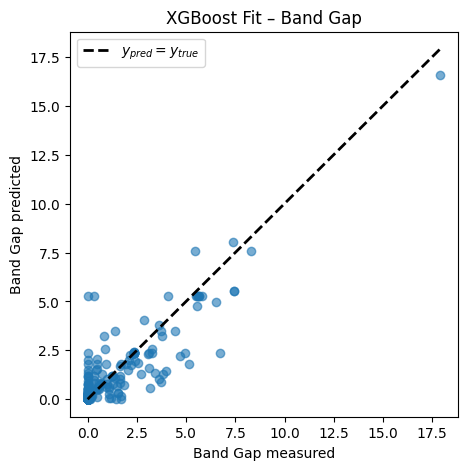

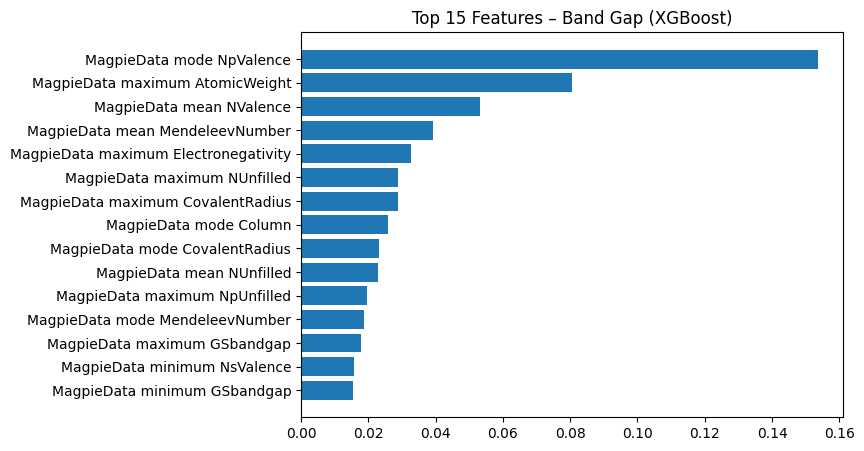


Train Sample Results – Formation Energy:
MAE: 0.077, R^2: 0.947

Test Sample Results – Formation Energy:
MAE: 0.222, R^2: 0.846



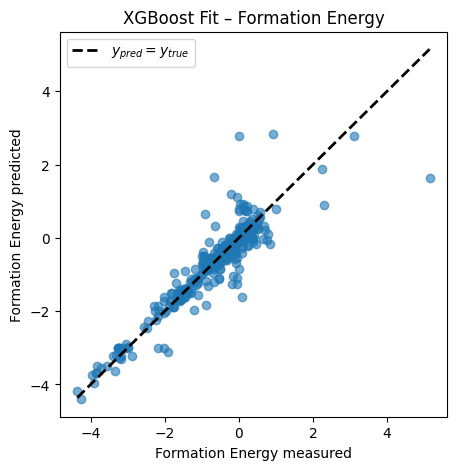

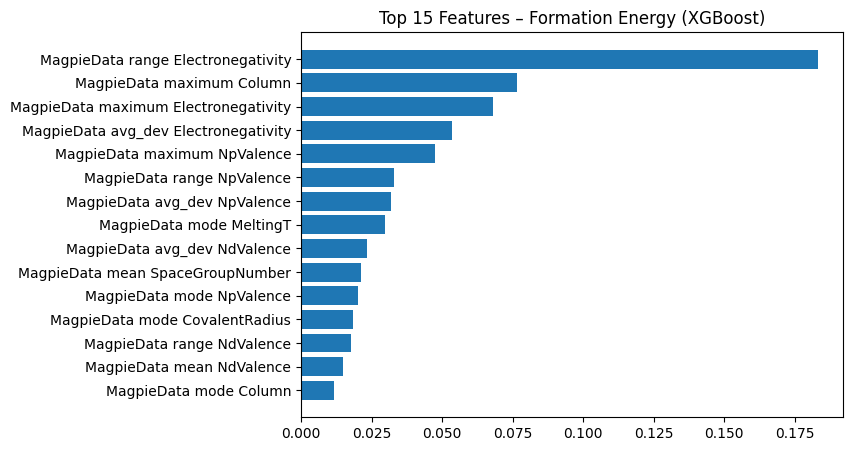


Train Sample Results – Fermi Energy:
MAE: 0.384, R^2: 0.913

Test Sample Results – Fermi Energy:
MAE: 1.075, R^2: 0.712



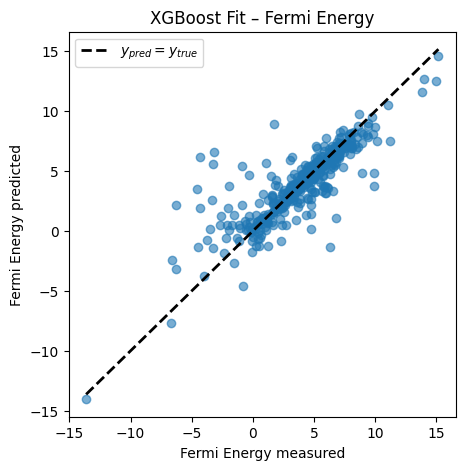

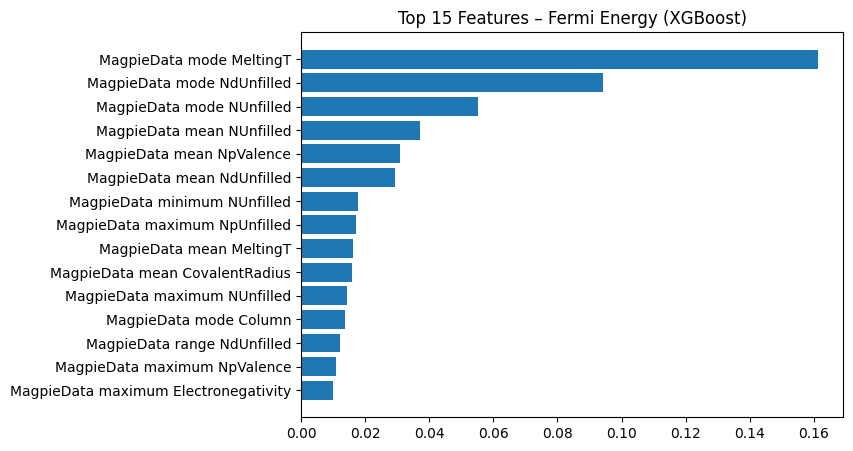


Train Sample Results – Total Magnetization:
MAE: 0.921, R^2: 0.811

Test Sample Results – Total Magnetization:
MAE: 2.120, R^2: 0.110



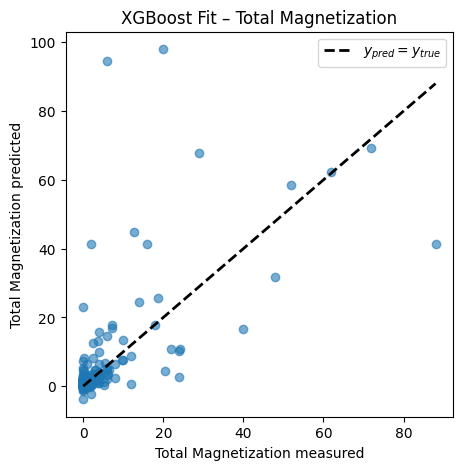

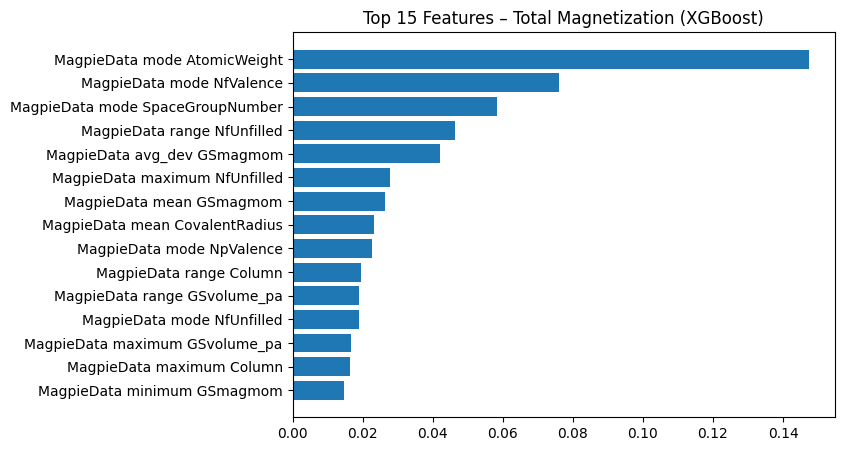


Train Sample Results – Is Magnetic:
Accuracy: 0.987

Test Sample Results – Is Magnetic:
Accuracy: 0.915



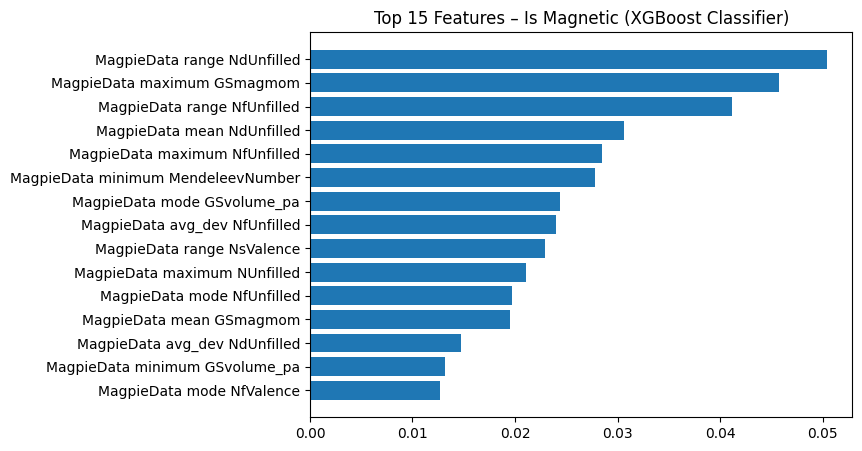


Train Sample Results – Is Metal / Semiconductor:
Accuracy: 0.973

Test Sample Results – Is Metal / Semiconductor:
Accuracy: 0.887



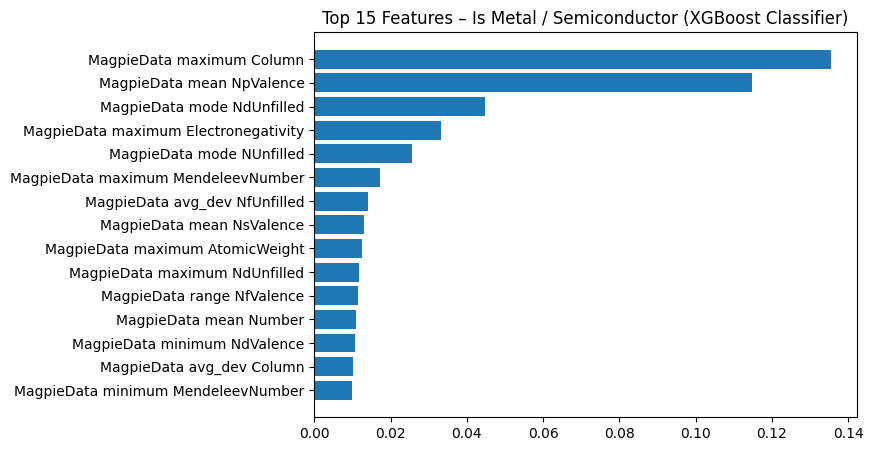

In [ ]:
def xgb_regression(X, y, name, clip_zero=False):

    #remove Nans
    mask = y.notna()
    X_clean = X.loc[mask]
    y_clean = y.loc[mask]

    X_train, X_test, y_train, y_test = train_test_split(X_clean, y_clean, test_size=0.2, random_state=42)

    # XGBoost model
    xgb = XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=8,
        subsample=0.8,        # 80% training
        colsample_bytree=0.8, # 80% features -- diversity among trees
        random_state=42
    )

    xgb.fit(X_train, y_train)

    # Train
    y_pred_train = xgb.predict(X_train)
    if clip_zero:
        y_pred_train = np.clip(y_pred_train, a_min=0, a_max=None)

    mae_train = mean_absolute_error(y_train, y_pred_train)
    r2_train = r2_score(y_train, y_pred_train)

    print(f"\nTrain Sample Results – {name}:")
    print(f"MAE: {mae_train:.3f}, R^2: {r2_train:.3f}")

    # Test
    y_pred_test = xgb.predict(X_test)
    if clip_zero:
        y_pred_test = np.clip(y_pred_test, a_min=0, a_max=None)

    mae_test = mean_absolute_error(y_test, y_pred_test)
    r2_test = r2_score(y_test, y_pred_test)

    print(f"\nTest Sample Results – {name}:")
    print(f"MAE: {mae_test:.3f}, R^2: {r2_test:.3f}\n")


    plt.figure(figsize=(5,5))
    plt.scatter(y_test, y_pred_test, alpha=0.6)

    # y = x
    y_all = y_test.values
    identity = np.linspace(y_all.min(), y_all.max(), 100)
    plt.plot(identity, identity, 'k--', linewidth=2,label='$y_{pred}=y_{true}$')

    plt.xlabel(f"{name} measured")
    plt.ylabel(f"{name} predicted")
    plt.title(f"XGBoost Fit – {name}")

    plt.legend()
    plt.show()


    # ------------------ Feature importance ------------------
    importances = xgb.feature_importances_
    indices = np.argsort(importances)[-15:]  # top 15

    plt.figure(figsize=(7,5))
    plt.barh(range(len(indices)), importances[indices])
    plt.yticks(range(len(indices)), X.columns[indices])
    plt.title(f"Top 15 Features – {name} (XGBoost)")
    plt.show()

    return xgb

def xgb_classification(X, y, name):

    mask = y.notna()
    X_clean = X.loc[mask]
    y_clean = y.loc[mask]

    X_train, X_test, y_train, y_test = train_test_split(X_clean, y_clean, test_size=0.2, random_state=42)

    xgb_clf = XGBClassifier(
        n_estimators=500,
        max_depth=8,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='logloss',
        random_state=42
    )

    xgb_clf.fit(X_train, y_train)

    # Train
    y_pred_train = xgb_clf.predict(X_train)
    acc_train = accuracy_score(y_train, y_pred_train)
    print(f"\nTrain Sample Results – {name}:")
    print(f"Accuracy: {acc_train:.3f}")

    # Test
    y_pred_test = xgb_clf.predict(X_test)
    acc_test = accuracy_score(y_test, y_pred_test)
    print(f"\nTest Sample Results – {name}:")
    print(f"Accuracy: {acc_test:.3f}\n")

    # ------------------ Feature importance ------------------
    importances = xgb_clf.feature_importances_
    indices = np.argsort(importances)[-15:]  # top 15

    plt.figure(figsize=(7,5))
    plt.barh(range(len(indices)), importances[indices])
    plt.yticks(range(len(indices)), X.columns[indices])
    plt.title(f"Top 15 Features – {name} (XGBoost Classifier)")
    plt.show()

    return xgb_clf


# Properties
xgb_bandgap = xgb_regression(X_numeric, y_bandgap, "Band Gap", clip_zero=True)

xgb_formation = xgb_regression(X_numeric, y_formation, "Formation Energy")

xgb_efermi = xgb_regression(X_numeric, y_efermi, "Fermi Energy")

xgb_magnetization = xgb_regression(X_numeric, y_magnetization, "Total Magnetization")

xgb_is_magnetic = xgb_classification(X_numeric, y_is_magnetic, "Is Magnetic")

xgb_is_metal = xgb_classification(X_numeric, y_metal, "Is Metal / Semiconductor")

---

### K-cross validation method

---

Set 1 – Band Gap (eV)
   R^2: 0.7769
Set 2 – Band Gap (eV)
   R^2: 0.5866
Set 3 – Band Gap (eV)
   R^2: 0.6074
Set 4 – Band Gap (eV)
   R^2: 0.7045
Set 5 – Band Gap (eV)
   R^2: 0.6802

Final Results: Band Gap (eV)
Average R^2 (5 sets): 0.6711
R^2 standard deviation: 0.0687


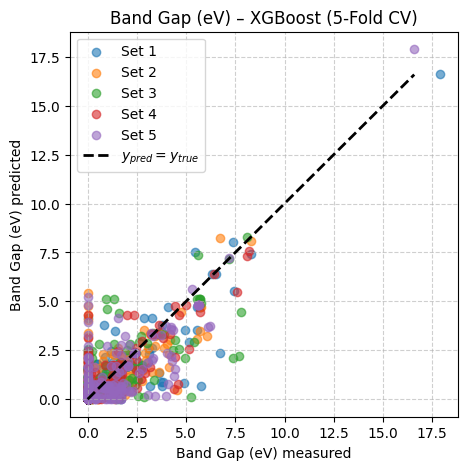

Set 1 – Formation Energy (eV/atom)
   R^2: 0.8394
Set 2 – Formation Energy (eV/atom)
   R^2: 0.8851
Set 3 – Formation Energy (eV/atom)
   R^2: 0.8354
Set 4 – Formation Energy (eV/atom)
   R^2: 0.7908
Set 5 – Formation Energy (eV/atom)
   R^2: 0.8514

Final Results: Formation Energy (eV/atom)
Average R^2 (5 sets): 0.8404
R^2 standard deviation: 0.0303


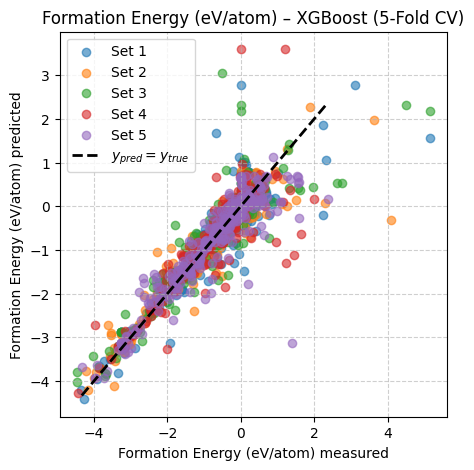

Set 1 – Fermi Energy (eV)
   R^2: 0.7643
Set 2 – Fermi Energy (eV)
   R^2: 0.6544
Set 3 – Fermi Energy (eV)
   R^2: 0.6560
Set 4 – Fermi Energy (eV)
   R^2: 0.6354
Set 5 – Fermi Energy (eV)
   R^2: 0.7369

Final Results: Fermi Energy (eV)
Average R^2 (5 sets): 0.6894
R^2 standard deviation: 0.0512


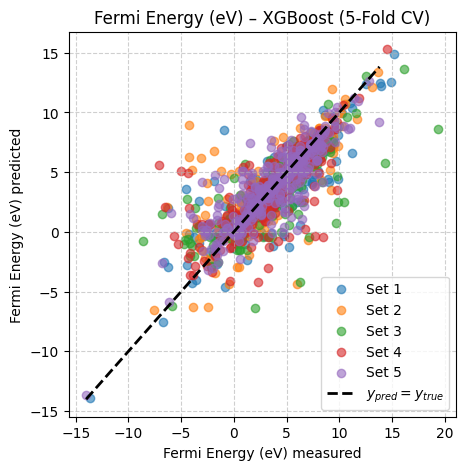

Set 1 – Total Magnetization (μB)
   R^2: 0.1357
Set 2 – Total Magnetization (μB)
   R^2: 0.3689
Set 3 – Total Magnetization (μB)
   R^2: 0.2869
Set 4 – Total Magnetization (μB)
   R^2: 0.1485
Set 5 – Total Magnetization (μB)
   R^2: 0.1451

Final Results: Total Magnetization (μB)
Average R^2 (5 sets): 0.2170
R^2 standard deviation: 0.0943


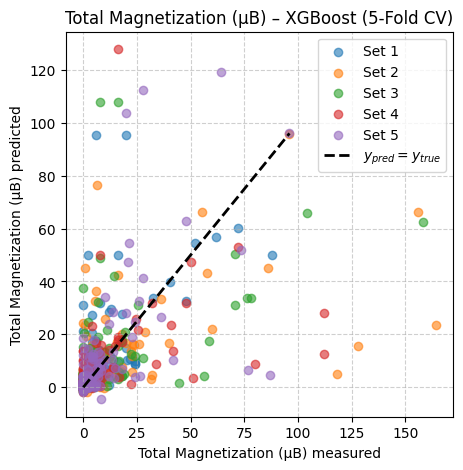

Set 1 – Magnetic vs Non Magnetic...
   Accuracy: 0.9025
Set 2 – Magnetic vs Non Magnetic...
   Accuracy: 0.8900
Set 3 – Magnetic vs Non Magnetic...
   Accuracy: 0.9000
Set 4 – Magnetic vs Non Magnetic...
   Accuracy: 0.8775
Set 5 – Magnetic vs Non Magnetic...
   Accuracy: 0.8825

Final Results – Magnetic vs Non Magnetic
Average accuracy (5 folds): 0.8905
Accuracy standard deviation: 0.0097

Set 1 – Metal vs Semiconductor...
   Accuracy: 0.8725
Set 2 – Metal vs Semiconductor...
   Accuracy: 0.8875
Set 3 – Metal vs Semiconductor...
   Accuracy: 0.8750
Set 4 – Metal vs Semiconductor...
   Accuracy: 0.8675
Set 5 – Metal vs Semiconductor...
   Accuracy: 0.8425

Final Results – Metal vs Semiconductor
Average accuracy (5 folds): 0.8690
Accuracy standard deviation: 0.0148



[0.8725, 0.8875, 0.875, 0.8675, 0.8425]

In [ ]:
def xgb_kfold_regression(X_numeric, y, name, K, clip_zero=False):

    mask = y.notna()
    X_clean = X_numeric.loc[mask]
    y_clean = y.loc[mask]

    kf = KFold(n_splits=K, shuffle=True, random_state=42)

    modelo = XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=8,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42
    )

    fold_scores = []
    colors = plt.cm.tab10.colors

    plt.figure(figsize=(5, 5))

    for i, (train_index, test_index) in enumerate(kf.split(X_clean)):
        print(f"Set {i+1} – {name}")

        X_train, X_test = X_clean.iloc[train_index], X_clean.iloc[test_index]
        y_train, y_test = y_clean.iloc[train_index], y_clean.iloc[test_index]

        modelo.fit(X_train, y_train)

        y_pred = modelo.predict(X_test)

        if clip_zero:
            y_pred = np.clip(y_pred, a_min=0, a_max=None)

        r2 = r2_score(y_test, y_pred)
        fold_scores.append(r2)

        print(f"   R^2: {r2:.4f}")

        plt.scatter(y_test.values, y_pred, alpha=0.6, color=colors[i % len(colors)], label=f'Set {i+1}')

    # y = x
    y_all = y_test.values
    identity = np.linspace(y_all.min(), y_all.max(), 100)
    plt.plot(identity, identity, 'k--', linewidth=2,
             label='$y_{pred}=y_{true}$')

    print("\nFinal Results:", name)
    print(f"Average R^2 ({K} sets): {np.mean(fold_scores):.4f}")
    print(f"R^2 standard deviation: {np.std(fold_scores):.4f}")

    plt.xlabel(f"{name} measured")
    plt.ylabel(f"{name} predicted")
    plt.title(f"{name} – XGBoost ({K}-Fold CV)")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

    return fold_scores

# CLASSIFICATION ------------------------------------
def xgb_kfold_classification(X, y, name, K):

    kf = KFold(n_splits=K, shuffle=True, random_state=42)

    modelo = XGBClassifier(
    n_estimators=500,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42
    )

    accuracies = []

    for i, (train_index, test_index) in enumerate(kf.split(X)):
        print(f"Set {i+1} – {name}...")

        X_train, X_test = X.iloc[train_index], X.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]

        modelo.fit(X_train, y_train)
        y_pred = modelo.predict(X_test)

        acc = accuracy_score(y_test, y_pred)
        accuracies.append(acc)

        print(f"   Accuracy: {acc:.4f}")

    print(f"\nFinal Results – {name}")
    print(f"Average accuracy ({K} folds): {np.mean(accuracies):.4f}")
    print(f"Accuracy standard deviation: {np.std(accuracies):.4f}\n")

    return accuracies

#---------------------------------------- PROPERTIES ----------------------------------------

scores_bandgap = xgb_kfold_regression(
    X_numeric,
    y_bandgap,
    "Band Gap (eV)", 5,
    clip_zero=True
)

scores_formation = xgb_kfold_regression(
    X_numeric,
    y_formation,
    "Formation Energy (eV/atom)",5
)

scores_efermi = xgb_kfold_regression(
    X_numeric,
    y_efermi,
    "Fermi Energy (eV)",5
)


scores_magnetization = xgb_kfold_regression(
    X_numeric,
    y_magnetization,
    "Total Magnetization (μB)",5
)

xgb_kfold_classification(
    X,
    data_features["is_magnetic"].astype(int),
    "Magnetic vs Non Magnetic",5
)

y_metal = (data_features["band_gap"] < 0.01).astype(int)

xgb_kfold_classification(
    X,
    y_metal,
    "Metal vs Semiconductor",5
)




---

# Model 3: Neural Networks

---

---
### Training/Test = 80/20 %
---

In [ ]:
!pip install pytorch-lightning

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.5/849.5 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 42.6 MB/s eta 0:00:00


[Band Gap] Epoch 20, Val Loss: 0.3178
[Band Gap] Epoch 40, Val Loss: 0.3263
[Band Gap] Epoch 43, Val Loss: 0.3144
--> Early stopping in Epoch 43

Band Gap - Final: Train MAE = 0.240, R^2 = 0.743
 Test MAE = 0.314, R^2 = 0.719

[Formation Energy] Epoch 20, Val Loss: 0.2167
[Formation Energy] Epoch 40, Val Loss: 0.2092
[Formation Energy] Epoch 60, Val Loss: 0.2032
[Formation Energy] Epoch 61, Val Loss: 0.2141
--> Early stopping in Epoch 61

Formation Energy - Final: Train MAE = 0.153, R^2 = 0.893
 Test MAE = 0.214, R^2 = 0.846

[Fermi Energy] Epoch 20, Val Loss: 1.1836
[Fermi Energy] Epoch 40, Val Loss: 1.1160
[Fermi Energy] Epoch 60, Val Loss: 1.0560
[Fermi Energy] Epoch 80, Val Loss: 1.0320
[Fermi Energy] Epoch 100, Val Loss: 1.0228
[Fermi Energy] Epoch 103, Val Loss: 1.0414
--> Early stopping in Epoch 103

Fermi Energy - Final: Train MAE = 0.710, R^2 = 0.825
 Test MAE = 1.041, R^2 = 0.756

[Total Magnetization] Epoch 20, Val Loss: 1.9899
[Total Magnetization] Epoch 40, Val Loss: 1.906

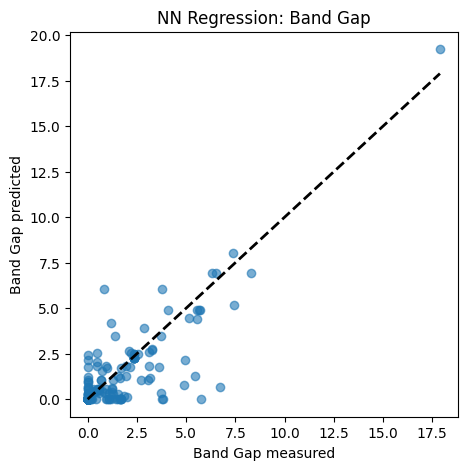

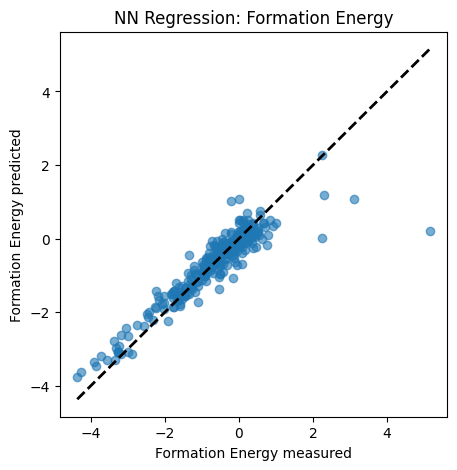

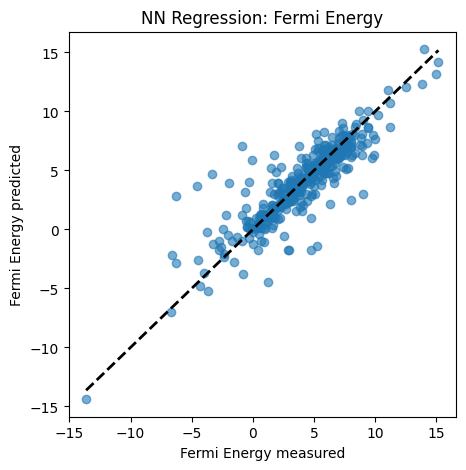

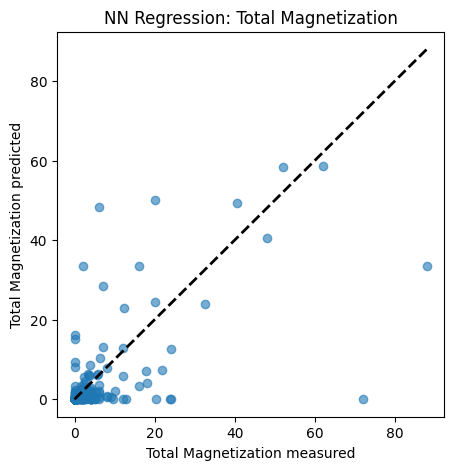

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class EarlyStopping:
    def __init__(self, patience=20, min_delta=0.0001):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False

    def __call__(self, val_loss):
        if self.best_loss is None:
            self.best_loss = val_loss
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.counter = 0

class RegressionNN(nn.Module):
    def __init__(self, input_size, dropout_rate=0.1):
        super(RegressionNN, self).__init__()
        self.layer_1 = nn.Sequential(nn.Linear(input_size, 128), nn.ReLU(), nn.Dropout(dropout_rate))
        self.layer_2 = nn.Sequential(nn.Linear(128, 64), nn.ReLU(), nn.Dropout(dropout_rate))
        self.output_layer = nn.Linear(64, 1)

    def forward(self, x):
        x = self.layer_1(x)
        x = self.layer_2(x)
        return self.output_layer(x)

def train_regression_nn(X, y, name, num_epochs=200, batch_size=32, learning_rate=0.001, clip_zero=False, dropout_rate=0.1, patience=20):

    mask = y.notna()
    X_clean = X.loc[mask]
    y_clean = y.loc[mask]

    X_train_raw, X_test_raw, y_train, y_test = train_test_split(X_clean, y_clean, test_size=0.2, random_state=42)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_raw)
    X_test_scaled = scaler.transform(X_test_raw)

    X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
    y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1,1).to(device)
    X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
    y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1,1).to(device)

    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

    model = RegressionNN(X_clean.shape[1], dropout_rate=dropout_rate).to(device)
    criterion = nn.L1Loss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    early_stopper = EarlyStopping(patience=patience, min_delta=0.0001)

    for epoch in range(num_epochs):
        model.train()
        epoch_losses = []
        for inputs, targets in train_loader:
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            epoch_losses.append(loss.item())

        model.eval()
        with torch.no_grad():
            val_outputs = model(X_test_tensor)
            val_loss = criterion(val_outputs, y_test_tensor).item()

        # Check Early Stopping
        early_stopper(val_loss)

        if (epoch + 1) % 20 == 0 or early_stopper.early_stop:
            print(f"[{name}] Epoch {epoch+1}, Val Loss: {val_loss:.4f}")

        if early_stopper.early_stop:
            print(f"--> Early stopping in Epoch {epoch+1}")
            break

    # Final
    model.eval()
    with torch.no_grad():
        y_pred_train = model(X_train_tensor).cpu().numpy()
        y_pred_test = model(X_test_tensor).cpu().numpy()

        if clip_zero:
            y_pred_train = np.clip(y_pred_train, 0, None)
            y_pred_test = np.clip(y_pred_test, 0, None)

        mae_train = mean_absolute_error(y_train, y_pred_train)
        r2_train = r2_score(y_train, y_pred_train)
        mae_test = mean_absolute_error(y_test, y_pred_test)
        r2_test = r2_score(y_test, y_pred_test)

    print(f"\n{name} - Final: Train MAE = {mae_train:.3f}, R^2 = {r2_train:.3f}\n Test MAE = {mae_test:.3f}, R^2 = {r2_test:.3f}\n")

    return {
        "model": model, "scaler": scaler, "mae_test": mae_test, "r2_test": r2_test,
        "y_train": y_train, "y_pred_train": y_pred_train,
        "y_test": y_test, "y_pred_test": y_pred_test
    }

# ==================== ALL PROPERTIES ====================
nn_bandgap_results = train_regression_nn(X_numeric, y_bandgap, "Band Gap", clip_zero=True, dropout_rate=0.2)  # dropout calculated by k-folds validation (cell below)
nn_formation_results = train_regression_nn(X_numeric, y_formation, "Formation Energy", clip_zero=False, dropout_rate=0.1)
nn_efermi_results = train_regression_nn(X_numeric, y_efermi, "Fermi Energy", clip_zero=False, dropout_rate=0.1)
nn_magnetization_results = train_regression_nn(X_numeric, y_magnetization, "Total Magnetization", clip_zero=False, dropout_rate=0.1)

test_nn = {
    "Band Gap": nn_bandgap_results,
    "Formation Energy": nn_formation_results,
    "Fermi Energy": nn_efermi_results,
    "Total Magnetization": nn_magnetization_results}

# Plot
for name, res_dict in test_nn.items():

  y_train, y_pred_train, y_test, y_pred_test = res_dict["y_train"], res_dict["y_pred_train"], res_dict["y_test"], res_dict["y_pred_test"]

  plt.figure(figsize=(5,5))
  plt.scatter(y_test, y_pred_test, alpha=0.6)

  # y = x
  y_all = y_test.values
  identity = np.linspace(y_all.min(), y_all.max(), 100)
  plt.plot(identity, identity, 'k--', linewidth=2, label='$y_{pred}=y_{true}$')

  plt.xlabel(f"{name} measured")
  plt.ylabel(f"{name} predicted")
  plt.title(f"NN Regression: {name}")
  plt.show()

In [ ]:
class ClassificationNN(nn.Module):
    def __init__(self, input_size, dropout_rate=0.2):
        super(ClassificationNN, self).__init__()
        self.layer_1 = nn.Sequential(nn.Linear(input_size, 128), nn.ReLU(), nn.Dropout(dropout_rate))
        self.layer_2 = nn.Sequential(nn.Linear(128, 64), nn.ReLU(), nn.Dropout(dropout_rate))
        self.output_layer = nn.Linear(64, 1)

    def forward(self, x):
        x = self.layer_1(x)
        x = self.layer_2(x)
        return torch.sigmoid(self.output_layer(x))

def train_classification_nn(X, y, name, num_epochs=200, batch_size=32, learning_rate=0.001, dropout_rate=0.2, patience=20):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    mask = y.notna()
    X_clean = X.loc[mask]
    y_clean = y.loc[mask]

    X_train_raw, X_test_raw, y_train, y_test = train_test_split(X_clean, y_clean, test_size=0.2, random_state=42)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_raw)
    X_test_scaled = scaler.transform(X_test_raw)

    X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
    y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1,1).to(device)
    X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
    y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1,1).to(device)

    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

    model = ClassificationNN(X_clean.shape[1], dropout_rate=dropout_rate).to(device)
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    early_stopper = EarlyStopping(patience=patience)

    # Training loop
    for epoch in range(num_epochs):
        model.train()
        for inputs, targets in train_loader:
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # Check Early Stopping
        model.eval()
        with torch.no_grad():
            val_outputs = model(X_test_tensor)
            val_loss = criterion(val_outputs, y_test_tensor).item()

        early_stopper(val_loss)

        if (epoch + 1) % 20 == 0 or early_stopper.early_stop:
            print(f"[{name}] Epoch {epoch+1}, Val Loss: {val_loss:.4f}")

        if early_stopper.early_stop:
            print(f"--> Early stopping in Epoch {epoch+1}")
            break

    # Final
    model.eval()
    with torch.no_grad():
        y_pred_train_prob = model(X_train_tensor).cpu().numpy()
        y_pred_test_prob = model(X_test_tensor).cpu().numpy()

        y_pred_train = (y_pred_train_prob > 0.5).astype(int)
        y_pred_test = (y_pred_test_prob > 0.5).astype(int)

        acc_train = accuracy_score(y_train, y_pred_train)
        acc_test = accuracy_score(y_test, y_pred_test)

    print(f"\n{name} - Final Accuracy: Train = {acc_train:.3f}, Test = {acc_test:.3f}\n")


    return {
        "model": model,
        "scaler": scaler,
        "y_train": y_train,
        "y_pred_train": y_pred_train,
        "y_test": y_test,
        "y_pred_test": y_pred_test,
        "acc_train": acc_train,
        "acc_test": acc_test
    }

# Classification
nn_is_magnetic_results = train_classification_nn(X_numeric, y_is_magnetic, "Magnetic vs Non-magnetic", dropout_rate=0.2)
nn_metal_results = train_classification_nn(X_numeric, y_metal, "Metal vs Semiconductor", dropout_rate=0.2)

[Magnetic vs Non-magnetic] Epoch 20, Val Loss: 0.3306
[Magnetic vs Non-magnetic] Epoch 40, Val Loss: 0.3732
[Magnetic vs Non-magnetic] Epoch 41, Val Loss: 0.3522
--> Early stopping in Epoch 41

Magnetic vs Non-magnetic - Final Accuracy: Train = 0.942, Test = 0.877

[Metal vs Semiconductor] Epoch 20, Val Loss: 0.2802
[Metal vs Semiconductor] Epoch 29, Val Loss: 0.3490
--> Early stopping in Epoch 29

Metal vs Semiconductor - Final Accuracy: Train = 0.914, Test = 0.873



---
## K-cross validation

---

In [ ]:
def kfold_train_regression(X, y, input_size, num_epochs=50, batch_size=32, learning_rate=0.001, dropout_rate=0.3, n_splits=5):

    mask = y.notna()
    X_clean = X.loc[mask]
    y_clean = y.loc[mask]


    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    val_scores = []

    for fold, (train_idx, val_idx) in enumerate(kf.split(X_clean)):
        X_train, X_val = X_clean.iloc[train_idx], X_clean.iloc[val_idx]
        y_train, y_val = y_clean.iloc[train_idx], y_clean.iloc[val_idx]


        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_val_scaled = scaler.transform(X_val)

        X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
        y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1,1).to(device)
        X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32).to(device)
        y_val_tensor = torch.tensor(y_val.values, dtype=torch.float32).view(-1,1).to(device)


        model = RegressionNN(input_size, dropout_rate).to(device)
        optimizer = optim.Adam(model.parameters(), lr=learning_rate)
        criterion = nn.MSELoss()

        # Training
        for epoch in range(num_epochs):
            model.train()
            optimizer.zero_grad()
            outputs = model(X_train_tensor)
            loss = criterion(outputs, y_train_tensor)
            loss.backward()
            optimizer.step()

        # Validation
        model.eval()
        with torch.no_grad():
            y_val_pred = model(X_val_tensor).cpu().numpy()
        r2_val = r2_score(y_val, y_val_pred)
        val_scores.append(r2_val)
        #print(f"Fold {fold+1}: R^2 = {r2_val:.4f}")

    mean_r2 = np.mean(val_scores)
    #print(f"\nMean R^2 across {n_splits} folds: {mean_r2:.4f}")
    return mean_r2

def kfold_train_classification(X, y, input_size, num_epochs=50, batch_size=32, learning_rate=0.001, dropout_rate=0.4, n_splits=5):

    mask = y.notna()
    X_clean = X.loc[mask]
    y_clean = y.loc[mask]


    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    val_scores = []

    for fold, (train_idx, val_idx) in enumerate(kf.split(X_clean)):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]


        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_val_scaled = scaler.transform(X_val)


        X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
        y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1,1).to(device)
        X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32).to(device)
        y_val_tensor = torch.tensor(y_val.values, dtype=torch.float32).view(-1,1).to(device)


        model = ClassificationNN(input_size, dropout_rate).to(device)
        optimizer = optim.Adam(model.parameters(), lr=learning_rate)
        criterion = nn.BCELoss()

        # Training
        for epoch in range(num_epochs):
            model.train()
            optimizer.zero_grad()
            outputs = model(X_train_tensor)
            loss = criterion(outputs, y_train_tensor)
            loss.backward()
            optimizer.step()

        # Validation
        model.eval()
        with torch.no_grad():
            y_val_pred = model(X_val_tensor).cpu().numpy() > 0.5
        acc_val = accuracy_score(y_val, y_val_pred)
        val_scores.append(acc_val)
        #print(f"Fold {fold+1}: Accuracy = {acc_val:.4f}")

    mean_acc = np.mean(val_scores)
    #print(f"\nMean accuracy across {n_splits} folds: {mean_acc:.4f}")
    return mean_acc

# PARAMETERS
dropouts = [0.1, 0.2, 0.3, 0.4]
num_epochs = 100

best_r2 = 0
best_params = None
print("Regression...\n")
yy = [y_bandgap, y_formation, y_efermi, y_magnetization]

for i, y in enumerate(yy):
  for dr in dropouts:
    r2 = kfold_train_regression(X_numeric, y, input_size=X_numeric.shape[1], dropout_rate=dr, num_epochs=num_epochs)
    if r2 > best_r2:
      best_r2 = r2
      best_params = {"dropout": dr}
  print(f"Best hyperparameters reg {i}:", best_params)
  print(f"Best R^2 reg {i}:", best_r2,"\n")


best_r2 = 0
best_params = None
print("Classification...\n")
yy2 = [y_is_magnetic, y_metal]

for i, y in enumerate(yy2):
  for dr in dropouts:
    r2 = kfold_train_classification(X_numeric, y, input_size=X_numeric.shape[1], dropout_rate=dr, num_epochs=num_epochs)
    if r2 > best_r2:
      best_r2 = r2
      best_params = {"dropout": dr}
  print(f"Best hyperparameters reg {i}:", best_params)
  print(f"Best R^2 reg {i}:", best_r2,"\n")

Regression...

Best hyperparameters reg 0: {'dropout': 0.1}
Best R^2 reg 0: 0.6691402604435307 

Best hyperparameters reg 1: {'dropout': 0.1}
Best R^2 reg 1: 0.8408980393258526 

Best hyperparameters reg 2: {'dropout': 0.1}
Best R^2 reg 2: 0.8408980393258526 

Best hyperparameters reg 3: {'dropout': 0.1}
Best R^2 reg 3: 0.8408980393258526 

Classification...

Best hyperparameters reg 0: {'dropout': 0.2}
Best R^2 reg 0: 0.8605 

Best hyperparameters reg 1: {'dropout': 0.2}
Best R^2 reg 1: 0.8605 



## Alternative to improve Band Gap Prediction

548
[Metal vs Semiconductor] Epoch 20, Val Loss: 0.3843
[Metal vs Semiconductor] Epoch 26, Val Loss: 0.6962
--> Early stopping in Epoch 26

Metal vs Semiconductor - Final Accuracy: Train = 0.932, Test = 0.850

[Band Gap (predicted semiconductors - TRAIN)] Epoch 20, Val Loss: 1.1010
[Band Gap (predicted semiconductors - TRAIN)] Epoch 28, Val Loss: 1.1259
--> Early stopping in Epoch 28

Band Gap (predicted semiconductors - TRAIN) - Final: Train MAE = 0.727, R^2 = 0.670
 Test MAE = 1.126, R^2 = 0.201

True semiconductors in Test: 103
Predicted semiconductors in Test: 101


MAE FINAL: 0.8819132615127185
R^2 FINAL: 0.7697364132401132


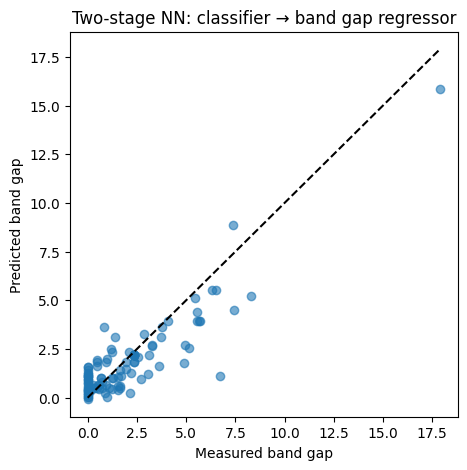

In [ ]:
## === First identify semiconductors and then predict its band gap === #

# Train classification of semiconductors
X_train, X_test, y_metal_train, y_metal_test, y_gap_train, y_gap_test = train_test_split(X_numeric, y_metal, y_bandgap, test_size=0.2, random_state=42)

semiconductor_mask = (y_metal == 0)
X_semiconductors = X_numeric.loc[semiconductor_mask]
print(len(X_semiconductors))

nn_metal_results = train_classification_nn(X_train, y_metal_train, "Metal vs Semiconductor")
metal_model = nn_metal_results["model"]
metal_scaler = nn_metal_results["scaler"]
metal_model.eval()


X_train_scaled = metal_scaler.transform(X_train)
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)

with torch.no_grad():
    p_metal_train = metal_model(X_train_tensor).cpu().numpy().flatten()

# mask (in order)
sc_pred_train = pd.Series(p_metal_train < 0.5, index=X_train.index)
X_train_sc = X_train.loc[sc_pred_train]
y_gap_train_sc = y_gap_train.loc[sc_pred_train]

# Train regression with results of classification
nn_bandgap_sc_results = train_regression_nn(
    X_train_sc,
    y_gap_train_sc,
    name="Band Gap (predicted semiconductors - TRAIN)",
    clip_zero=True
)

gap_model = nn_bandgap_sc_results["model"]
gap_scaler = nn_bandgap_sc_results["scaler"]
gap_model.eval()


# TEST --- similar
X_test_scaled = metal_scaler.transform(X_test)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)

with torch.no_grad():
    p_metal_test = metal_model(X_test_tensor).cpu().numpy().flatten()

sc_pred_test = pd.Series(p_metal_test < 0.5, index=X_test.index)
X_test_sc = X_test.loc[sc_pred_test]
y_gap_test_sc = y_gap_test.loc[sc_pred_test]


X_gap_scaled = gap_scaler.transform(X_test_sc)
X_gap_tensor = torch.tensor(X_gap_scaled, dtype=torch.float32).to(device)

with torch.no_grad():
    y_gap_pred = gap_model(X_gap_tensor).cpu().numpy().flatten()

print("True semiconductors in Test:", (y_metal_test == 0).sum())
print("Predicted semiconductors in Test:", sc_pred_test.sum())

print("\n\nMAE FINAL:", mean_absolute_error(y_gap_test_sc, y_gap_pred))
print("R^2 FINAL:", r2_score(y_gap_test_sc, y_gap_pred))

plt.figure(figsize=(5,5))
plt.scatter(y_gap_test_sc, y_gap_pred, alpha=0.6)

identity = np.linspace(y_gap_test_sc.min(), y_gap_test_sc.max(), 100)
plt.plot(identity, identity, 'k--')

plt.xlabel("Measured band gap")
plt.ylabel("Predicted band gap")
plt.title("Two-stage NN: classifier → band gap regressor")
plt.show()



---

# Ensemble 1: Randoom Forest  + XGBoost

---

In [ ]:
def ensemble_rf_xgb(X, y_true, name, rf_model, xgb_model, clip_zero=False):

    y_rf = rf_model.predict(X)
    y_xgb = xgb_model.predict(X)

    y_ens_2_models = (y_rf + y_xgb) / 2

    if clip_zero:
        y_ens_2_models = np.clip(y_ens_2_models, 0, None)

    # (For later cells)
    if y_true is not None:
        mask = y_true.notna()
        y_true_clean = y_true[mask]
        y_ens_2_models_clean = y_ens_2_models[mask]

        r2 = r2_score(y_true_clean, y_ens_2_models_clean)
        mae = mean_absolute_error(y_true_clean, y_ens_2_models_clean)

        print(f"{name} Ensemble → MAE = {mae:.3f}, R^2 = {r2:.3f}")

    return y_ens_2_models

# all properties
y_ensemble_rf_xgb = np.empty((6, X_numeric.shape[0]))

# Band Gap
y_ensemble_rf_xgb[0,:] = ensemble_rf_xgb(
    X_numeric, y_bandgap, "Band Gap", rf_bandgap, xgb_bandgap, clip_zero=True
)

# Formation Energy
y_ensemble_rf_xgb[1,:] = ensemble_rf_xgb(
    X_numeric, y_formation, "Formation Energy", rf_formation, xgb_formation, clip_zero=False
)

# Fermi Energy
y_ensemble_rf_xgb[2,:] = ensemble_rf_xgb(
    X_numeric, y_efermi, "Fermi Energy", rf_efermi, xgb_efermi, clip_zero=False
)

# Total Magnetization
y_ensemble_rf_xgb[3,:] = ensemble_rf_xgb(
    X_numeric, y_magnetization, "Total Magnetization", rf_magnetization, xgb_magnetization, clip_zero=False
)

y_ensemble_rf_xgb[4,:] = ensemble_rf_xgb(
    X_numeric, y_is_magnetic, "Is Magnetic", rf_is_magnetic, xgb_is_magnetic, clip_zero=False
)

y_ensemble_rf_xgb[5,:] = ensemble_rf_xgb(
    X_numeric, y_metal, "Metal", rf_metal, xgb_is_metal, clip_zero=False
)

Band Gap Ensemble → MAE = 0.187, R^2 = 0.872
Formation Energy Ensemble → MAE = 0.117, R^2 = 0.928
Fermi Energy Ensemble → MAE = 0.574, R^2 = 0.881
Total Magnetization Ensemble → MAE = 1.391, R^2 = 0.748
Is Magnetic Ensemble → MAE = 0.029, R^2 = 0.867
Metal Ensemble → MAE = 0.047, R^2 = 0.781


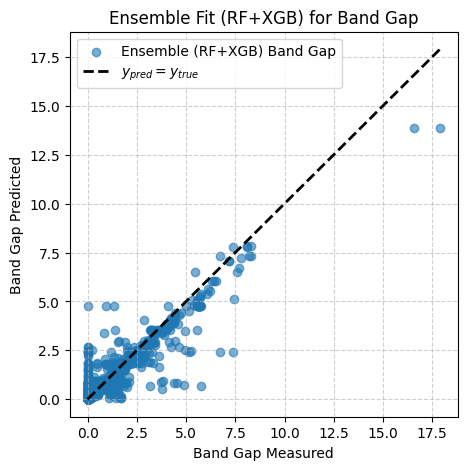

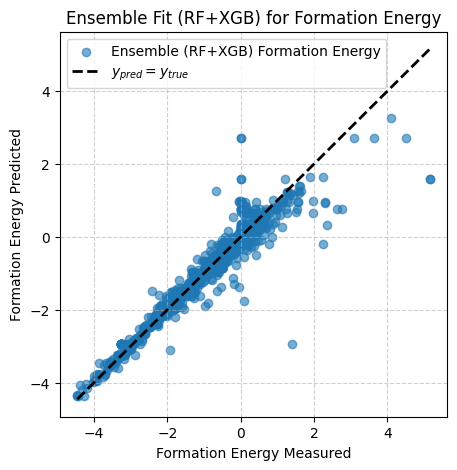

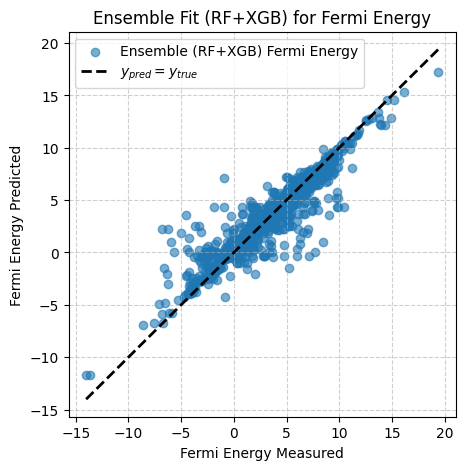

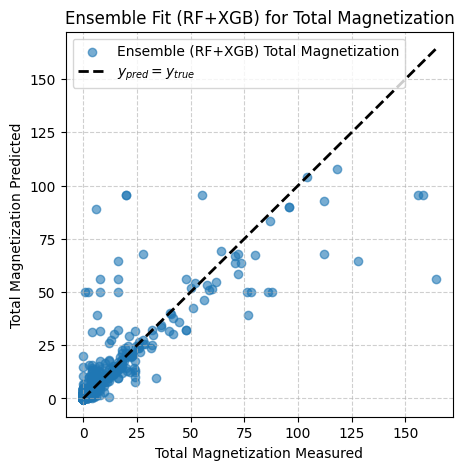

In [ ]:
properties_1_models = {
    "Band Gap": {"y_true": y_bandgap, "y_pred_ensemble": y_ensemble_rf_xgb[0,:]},
    "Formation Energy": {"y_true": y_formation, "y_pred_ensemble": y_ensemble_rf_xgb[1,:]},
    "Fermi Energy": {"y_true": y_efermi, "y_pred_ensemble": y_ensemble_rf_xgb[2,:]},
    "Total Magnetization": {"y_true": y_magnetization, "y_pred_ensemble": y_ensemble_rf_xgb[3,:]},
    "Is Magnetic": {"y_true": y_is_magnetic, "y_pred_ensemble": y_ensemble_rf_xgb[4,:]},
    "Metal": {"y_true": y_metal, "y_pred_ensemble": y_ensemble_rf_xgb[5,:]}
}

for name, data in list(properties_1_models.items())[0:4]: # Fixed: Convert to list before slicing
    y_true_plot = data["y_true"]
    y_pred_plot = data["y_pred_ensemble"]

    mask_plot = y_true_plot.notna()
    y_true_plot_clean = y_true_plot[mask_plot]
    y_pred_plot_clean = y_pred_plot[mask_plot]

    plt.figure(figsize=(5,5))
    plt.scatter(y_true_plot_clean, y_pred_plot_clean, alpha=0.6, label=f'Ensemble (RF+XGB) {name}')

    # y = x
    y_all = y_true_plot_clean.values
    identity = np.linspace(y_all.min(), y_all.max(), 100)
    plt.plot(identity, identity, 'k--', linewidth=2, label='$y_{pred}=y_{true}$')

    plt.xlabel(f"{name} Measured")
    plt.ylabel(f"{name} Predicted")
    plt.title(f"Ensemble Fit (RF+XGB) for {name}")

    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()
    plt.show()

---

# Ensemble 2: Randoom Forest  + Neural Network + XGBoost

---

In [ ]:
def nn_predict(model, scaler, X):
    X_scaled = scaler.transform(X)
    X_tensor = torch.tensor(X_scaled, dtype=torch.float32).to(device)
    model.eval()
    with torch.no_grad():
        y_pred = model(X_tensor).cpu().numpy().flatten()
    return y_pred

def ensemble_2(X, y_true, name, rf_model, xgb_model, nn_model, nn_scaler, clip_zero: bool):

    y_rf = rf_model.predict(X)
    y_xgb = xgb_model.predict(X)
    y_nn = nn_predict(nn_model, nn_scaler, X)

    y_ens = (y_rf + y_xgb + y_nn) / 3

    if clip_zero:
        y_ens = np.clip(y_ens, 0, None)

    # (For later cells)
    if y_true is not None:
        mask = y_true.notna()
        y_true_clean = y_true[mask]
        y_ens_clean = y_ens[mask]

        r2 = r2_score(y_true_clean, y_ens_clean)
        mae = mean_absolute_error(y_true_clean, y_ens_clean)

        print(f"{name} Ensemble → MAE = {mae:.3f}, R^2 = {r2:.3f}")

    return y_ens


y_ensemble = np.empty((6, X_numeric.shape[0]))

y_ensemble_bandgap = ensemble_2(
    X_numeric,
    y_bandgap,
    "Band Gap",
    rf_bandgap,
    xgb_bandgap,
    nn_bandgap_results['model'],
    nn_bandgap_results['scaler'],
    clip_zero=True
)
y_ensemble[0,:] = y_ensemble_bandgap


y_ensemble_formation = ensemble_2(
    X_numeric,
    y_formation,
    "Formation Energy",
    rf_formation,
    xgb_formation,
    nn_formation_results['model'],
    nn_formation_results['scaler'],
    clip_zero=False
)
y_ensemble[1,:] = y_ensemble_formation


y_ensemble_efermi = ensemble_2(
    X_numeric,
    y_efermi,
    "Fermi Energy",
    rf_efermi,
    xgb_efermi,
    nn_efermi_results['model'],
    nn_efermi_results['scaler'],
    clip_zero=False
)
y_ensemble[2,:] = y_ensemble_efermi


y_ensemble_magnetization = ensemble_2(
    X_numeric,
    y_magnetization,
    "Magnetization",
    rf_magnetization,
    xgb_magnetization,
    nn_magnetization_results['model'],
    nn_magnetization_results['scaler'],
    clip_zero=False
)
y_ensemble[3,:] = y_ensemble_magnetization

y_ensemble_is_magnetic = ensemble_2(
    X_numeric,
    y_is_magnetic,
    "Is Magnetic",
    rf_is_magnetic,
    xgb_is_magnetic,
    nn_is_magnetic_results['model'],
    nn_is_magnetic_results['scaler'],
    clip_zero=False
)
y_ensemble[4,:] = y_ensemble_is_magnetic

y_ensemble_metal = ensemble_2(
    X_numeric,
    y_metal,
    "Metal",
    rf_metal,
    xgb_is_metal,
    nn_metal_results['model'],
    nn_metal_results['scaler'],
    clip_zero=False
)
y_ensemble[5,:] = y_ensemble_metal

Band Gap Ensemble → MAE = 0.201, R^2 = 0.858
Formation Energy Ensemble → MAE = 0.124, R^2 = 0.925
Fermi Energy Ensemble → MAE = 0.609, R^2 = 0.872
Magnetization Ensemble → MAE = 1.549, R^2 = 0.715
Is Magnetic Ensemble → MAE = 0.055, R^2 = 0.866
Metal Ensemble → MAE = 0.076, R^2 = 0.795


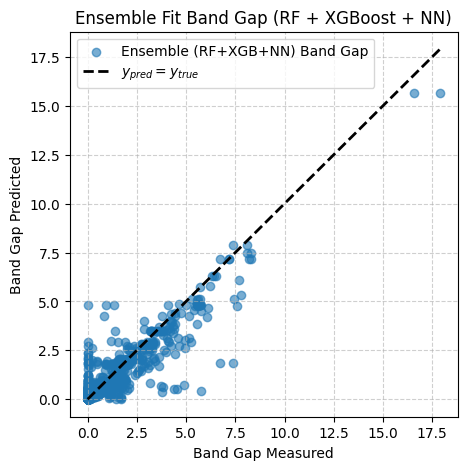

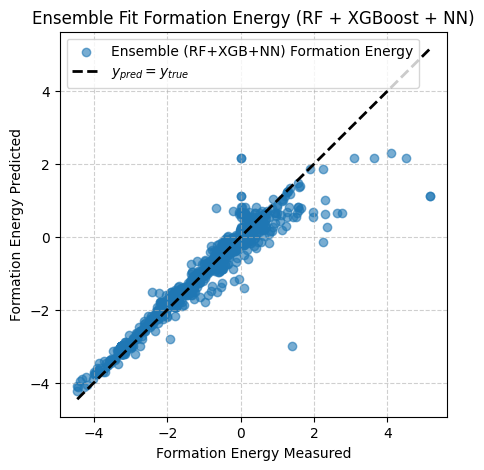

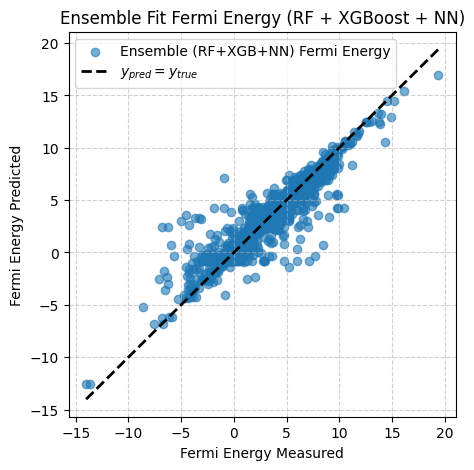

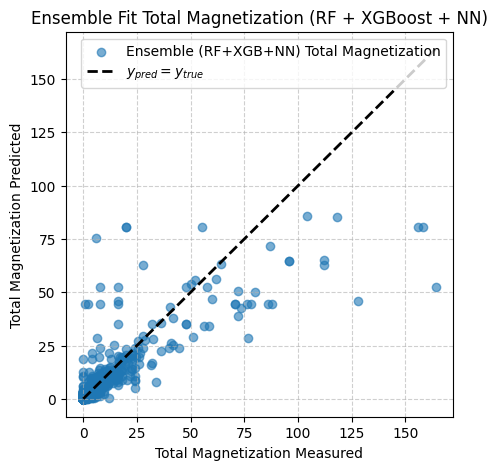

In [ ]:
properties = {
    "Band Gap": {"y_true": y_bandgap, "y_pred_ensemble": y_ensemble[0,:]},
    "Formation Energy": {"y_true": y_formation, "y_pred_ensemble": y_ensemble[1,:]},
    "Fermi Energy": {"y_true": y_efermi, "y_pred_ensemble": y_ensemble[2,:]},
    "Total Magnetization": {"y_true": y_magnetization, "y_pred_ensemble": y_ensemble[3,:]},
    "Is Magnetic": {"y_true": y_is_magnetic, "y_pred_ensemble": y_ensemble[4,:]},
    "Metal": {"y_true": y_metal, "y_pred_ensemble": y_ensemble[5,:]}
}

for name, data in list(properties.items())[0:4]:
    y_true_plot = data["y_true"]
    y_pred_plot = data["y_pred_ensemble"]

    mask_plot = y_true_plot.notna()
    y_true_plot_clean = y_true_plot[mask_plot]
    y_pred_plot_clean = y_pred_plot[mask_plot]

    plt.figure(figsize=(5, 5))
    plt.scatter(y_true_plot_clean, y_pred_plot_clean, alpha=0.6, label=f'Ensemble (RF+XGB+NN) {name}')

    # y = x
    y_all = y_true_plot_clean.values
    identity = np.linspace(y_all.min(), y_all.max(), 100)
    plt.plot(identity, identity, 'k--', linewidth=2, label='$y_{pred}=y_{true}$')

    plt.xlabel(f"{name} Measured")
    plt.ylabel(f"{name} Predicted")
    plt.title(f"Ensemble Fit {name} (RF + XGBoost + NN)")

    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()
    plt.show()

---

# Time

---

In [ ]:
import time
# For the 3-model ensemble (RF + XGBoost + NN) for Band Gap:
start = time.time()
y_pred_ensemble_3_models = ensemble_2(
    X_numeric,
    y_bandgap,
    "Band Gap",
    rf_bandgap,
    xgb_bandgap,
    nn_bandgap_results['model'],
    nn_bandgap_results['scaler'],
    clip_zero=True
)
end = time.time()

print(f"Ensemble (RF+XGB+NN) total prediction time: {end-start:.8f} seconds")
print(f"Ensemble (RF+XGB+NN) prediction time per sample: {(end-start)/len(X_numeric):.8f} seconds")

# For the 2-model ensemble (RF + XGBoost) for Band Gap:
start = time.time()
y_pred_ensemble_2_models = ensemble_rf_xgb(
    X_numeric, y_bandgap, "Band Gap", rf_bandgap, xgb_bandgap, clip_zero=True
)
end = time.time()

print(f"Ensemble (RF+XGB) total prediction time: {end-start:.8f} seconds")
print(f"Ensemble (RF+XGB) prediction time per sample: {(end-start)/len(X_numeric):.8f} seconds")

Band Gap Ensemble → MAE = 0.201, R^2 = 0.858
Ensemble (RF+XGB+NN) total prediction time: 0.43953228 seconds
Ensemble (RF+XGB+NN) prediction time per sample: 0.00021977 seconds
Band Gap Ensemble → MAE = 0.187, R^2 = 0.872
Ensemble (RF+XGB) total prediction time: 0.17573023 seconds
Ensemble (RF+XGB) prediction time per sample: 0.00008787 seconds


In [ ]:
!pip install ase gpaw pymatgen

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 13.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 65.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.5/71.5 MB 6.8 MB/s eta 0:00:00
  Created wheel for gpaw: filename=gpaw-25.7.0-cp312-cp312-linux_x86_64.whl size=2845227 sha256=f02740bd449b3127fff3ea7047c5e01139f7f257b02ac5f988b4635b813bc01f
  Stored in directory: /root/.cache/pip/wheels/59/7c/28/cb3306302de78987f064930ee3bac389062c0f87bfda50de21
Successfully built gpaw


In [ ]:
# This will take a while to run

from ase import Atoms
from gpaw import GPAW, PW, FermiDirac
import numpy as np

# ---------------- Simple Structure ----------------
atoms = Atoms(
    symbols=['Fe', 'Fe', 'O', 'O', 'O'],
    positions=[
        (0, 0, 0),
        (2.87, 2.87, 2.87),
        (1.43, 1.43, 0),
        (1.43, 0, 1.43),
        (0, 1.43, 1.43)
    ],
    cell=[5.74, 5.74, 5.74],
    pbc=True
)

calc = GPAW(
    mode=PW(300),              # cutoff to be faster
    xc='PBE',
    spinpol=True,
    occupations=FermiDirac(0.05),
    kpts=(2, 2, 2),
    maxiter=80,
    txt='fe2o3_fast.out'
)

atoms.calc = calc

# SCF (Self-Consistent Field) convergence
energy_total = atoms.get_potential_energy()
magnetization = atoms.get_magnetic_moment()

eigenvalues = calc.get_eigenvalues()
fermi = calc.get_fermi_level()

vb = max(eigenvalues[eigenvalues < fermi])
cb = min(eigenvalues[eigenvalues > fermi])
band_gap = cb - vb

print("Total energy (eV):", energy_total)
print("Toal magnetization (μB):", magnetization)
print("Band gap (eV):", band_gap)
print("Fermi Energy (eV):", fermi)

Total energy (eV): 1.3619439890790113
Toal magnetization (μB): 0.0004738819480586637
Band gap (eV): 0.021997529513772207
Fermi Energy (eV): -1.595332519162248


---

##Alternative to the convergence

---

In [ ]:
from gpaw import GPAW, LCAO

calc = GPAW(
    mode=LCAO(),
    basis='dzp',
    xc='PBE',
    spinpol=True,
    maxiter=20,
    txt='fe2o3_lcao.out'
)

atoms.calc = calc

import time

t0 = time.time()
try:
    atoms.get_potential_energy()
except Exception:
    pass
t1 = time.time()

print(f"DFT time (20 iterations SCF): {t1 - t0:.5f} sec.")
print(f"\n Average time per iteration: {(t1-t0)/20:.5f} sec.")

DFT time (20 iterations SCF): 41.79481 sec.

 Average time per iteration: 2.08974 sec.


Considering a typical number of 50–100 SCF iterations for convergence in Fe2O3, the total estimated time per DFT calculation is between 1 and 2 minutes.
(At least more than 80 are for the code above).